In [ ]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
import tensorflow as tf

print("GPUs disponibles:", len(tf.config.list_physical_devices('GPU')))
print(tf.config.list_physical_devices('GPU'))

GPUs disponibles: 0
[]


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

print("Todas las librerías se cargaron correctamente.")

Todas las librerías se cargaron correctamente.


In [ ]:
!pip install -q kaggle

In [ ]:
import os

print(os.getcwd())

/content


In [ ]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"oscarjramirezj","key":"dbe16b2222ab5ba33cc4e8bdcff49ce9"}'}

In [ ]:

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
# Verificar conexión con Kaggle

!kaggle datasets list -s fruits-360


ref                                                  title                                               size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------  --------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
moltean/fruits                                       Fruits-360 dataset                            8804326357  2026-10-27 08:32:54.893000         263524       3555                1  
barisyasli/fruit360                                  fruits-360                                     362079657  2020-04-22 01:53:20.160000            806          8           0.4375  
souro12/ccxzvv                                       Fruits Images - 5 classes                       15299044  2020-04-01 09:49:55.777000            888         10           0.8125  
ishandandekar/fruitimagedataset                      Fruit-Image-Dataset             

In [ ]:
!kaggle datasets download -d moltean/fruits

Dataset URL: https://www.kaggle.com/datasets/moltean/fruits
License(s): CC-BY-SA-4.0
100% 8.20G/8.20G [03:34<00:00, 41.1MB/s]



In [ ]:
!ls -lh /content

total 8.2G
-rw-r--r-- 1 root root 8.2G Oct 27 12:54 fruits.zip
-rw-r--r-- 1 root root   70 Nov  4 01:22 kaggle.json
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


In [ ]:
!unzip -l fruits.zip | head -30

Archive:  fruits.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
      728  2026-10-27 08:44   fruits-360_100x100/fruits-360/LICENSE
     7240  2026-10-27 08:44   fruits-360_100x100/fruits-360/README.md
     1867  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_103_100.jpg
     2087  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_107_100.jpg
     2093  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_111_100.jpg
     2111  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_115_100.jpg
     2168  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_119_100.jpg
     1707  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_11_100.jpg
     2077  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_123_100.jpg
     2085  2026-10-27 08:44   fruits-360_100x100/fruits-360/Test/Almonds 1/r0_127_100.jpg
     2075  2026-10-27 08:44   fruits-360_100x100/fru

In [ ]:

!unzip -l fruits.zip | grep "Train/" | head -100


In [ ]:
!mkdir fruits_dataset

mkdir: cannot create directory ‘fruits_dataset’: File exists


In [ ]:

!unzip -q fruits.zip -d fruits_dataset

In [ ]:
!ls fruits_dataset

fruits-360_100x100	   fruits-360_meta   fruits-360_original-size
fruits-360_3-body-problem  fruits-360_multi


In [ ]:

!ls fruits_dataset/fruits-360_100x100/fruits-360

LICENSE  README.md  Test  Training


In [ ]:
# Manejo de carpetas
import os

# Ruta entrenamiento
ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

# Obtener clases
clases = os.listdir(ruta_train)

# Mostrar cantidad
print("Número de clases:", len(clases))

Número de clases: 278


In [ ]:
for clase in sorted(clases)[:50]:
    print(clase)

Almonds 1
Apple 10
Apple 11
Apple 12
Apple 13
Apple 14
Apple 17
Apple 18
Apple 19
Apple 20
Apple 21
Apple 22
Apple 23
Apple 5
Apple 6
Apple 7
Apple 8
Apple 9
Apple Braeburn 1
Apple Crimson Snow 1
Apple Golden 1
Apple Golden 2
Apple Golden 3
Apple Granny Smith 1
Apple Pink Lady 1
Apple Red 1
Apple Red 2
Apple Red 3
Apple Red Delicious 1
Apple Red Yellow 1
Apple Red Yellow 2
Apricot 1
Avocado 1
Avocado 2
Avocado Black 1
Avocado Black 2
Avocado Green 1
Banana 1
Banana 2
Banana 3
Banana 4
Banana Lady Finger 1
Banana Red 1
Bean pod 1
Beetroot 1
BlackBerry 4
Blackberry 1
Blackberry 2
Blackberry 3
Blackberry 5


In [ ]:

for clase in sorted(clases):
    if ("Orange" in clase or
        "Grape" in clase or
        "Pineapple" in clase):
        print(clase)


Grape 1
Grape Blue 1
Grape Pink 1
Grape White 1
Grape White 2
Grape White 3
Grape White 4
Grape pink 2
Grapefruit Pink 1
Grapefruit White 1
Orange 1
Orange 2
Orange 3
Orange 5
Orange peeled 1
Pepper Orange 1
Pepper Orange 2
Pineapple 1
Pineapple Mini 1
Tomato Cherry Orange 1


In [ ]:

import os

print(os.getcwd())

/content


In [ ]:

!ls -lh /content

total 4.0K
drwxr-xr-x 1 root root 4.0K Nov  4 17:01 sample_data


In [ ]:

import os

ruta_train = "..."

clases_seleccionadas = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf      # Deep Learning
import numpy as np           # Cálculos numéricos
import pandas as pd          # Manejo de datos
import matplotlib.pyplot as plt  # Gráficas
import seaborn as sns        # Visualizaciones
from PIL import Image        # Procesar imágenes

print("Todas las librerías se cargaron correctamente.")

Todas las librerías se cargaron correctamente.


In [ ]:
!pip install -q kaggle

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets list -s fruits-360

ref                                                  title                                               size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------  --------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
moltean/fruits                                       Fruits-360 dataset                            8804326357  2026-10-27 08:32:54.893000         267490       3555                1  
barisyasli/fruit360                                  fruits-360                                     362079657  2020-04-22 01:53:20.160000            806          8           0.4375  
souro12/ccxzvv                                       Fruits Images - 5 classes                       15299044  2020-04-01 09:49:55.777000            888         10           0.8125  
ishandandekar/fruitimagedataset                      Fruit-Image-Dataset             

In [ ]:
!kaggle datasets download -d moltean/fruits

Dataset URL: https://www.kaggle.com/datasets/moltean/fruits
License(s): CC-BY-SA-4.0
100% 8.20G/8.20G [02:04<00:00, 70.9MB/s]



In [ ]:
!mkdir -p fruits_dataset
!unzip -q fruits.zip -d fruits_dataset

In [ ]:
!ls fruits_dataset

fruits-360_100x100	   fruits-360_meta   fruits-360_original-size
fruits-360_3-body-problem  fruits-360_multi


In [ ]:

!ls fruits_dataset/fruits-360_100x100/fruits-360

LICENSE  README.md  Test  Training


In [ ]:
import os

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

clases = os.listdir(ruta_train)

print("Número de clases:", len(clases))

Número de clases: 278


In [ ]:
# Contar imágenes por clase

import os

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

clases_seleccionadas = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

for clase in clases_seleccionadas:
    cantidad = len(os.listdir(os.path.join(ruta_train, clase)))
    print(f"{clase}: {cantidad} imágenes")

Apple Golden 1: 480 imágenes
Banana 1: 490 imágenes
Orange 1: 479 imágenes
Grape Blue 1: 984 imágenes
Pineapple 1: 490 imágenes


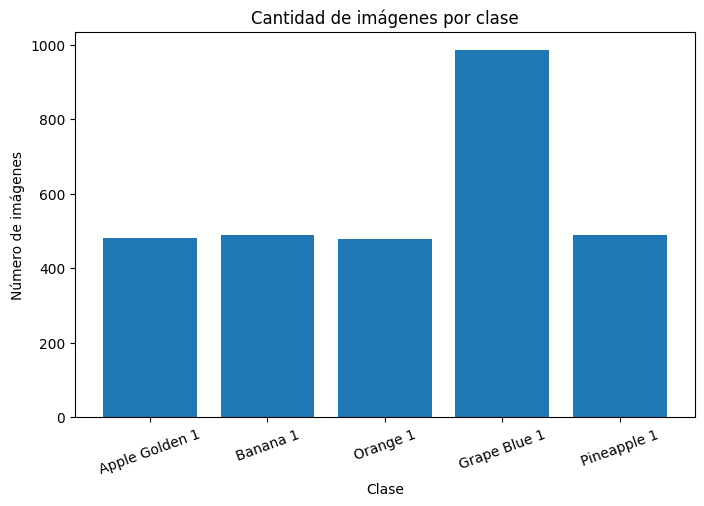

In [ ]:

import matplotlib.pyplot as plt

frutas = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

cantidades = [480, 490, 479, 984, 490]

plt.figure(figsize=(8,5))
plt.bar(frutas, cantidades)
plt.title("Cantidad de imágenes por clase")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=20)

plt.show()

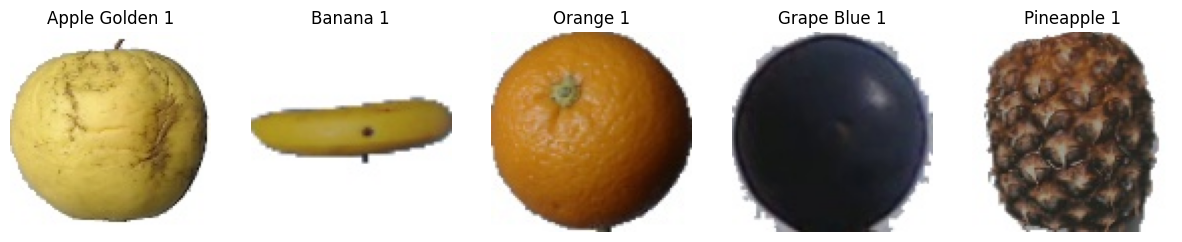

In [ ]:

import os
from PIL import Image
import matplotlib.pyplot as plt

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

clases_seleccionadas = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

plt.figure(figsize=(15,5))

for i, clase in enumerate(clases_seleccionadas):
    carpeta = os.path.join(ruta_train, clase)

    imagen = os.listdir(carpeta)[0]

    ruta_imagen = os.path.join(carpeta, imagen)

    img = Image.open(ruta_imagen)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(clase)
    plt.axis("off")

plt.show()

In [ ]:

import os
from PIL import Image

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

imagen = os.listdir(
    os.path.join(ruta_train, "Apple Golden 1")
)[0]

ruta_imagen = os.path.join(
    ruta_train,
    "Apple Golden 1",
    imagen
)

img = Image.open(ruta_imagen)

print("Dimensiones:", img.size)

Dimensiones: (100, 100)


In [ ]:

import os
from PIL import Image

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

imagen = os.listdir(
    os.path.join(ruta_train, "Apple Golden 1")
)[0]

ruta_imagen = os.path.join(
    ruta_train,
    "Apple Golden 1",
    imagen
)

img = Image.open(ruta_imagen)

print("Modo:", img.mode)

Modo: RGB


In [ ]:

import numpy as np

img_array = np.array(img)

print("Valor mínimo:", img_array.min())
print("Valor máximo:", img_array.max())

Valor mínimo: 0
Valor máximo: 255


In [ ]:

from tensorflow.keras.utils import image_dataset_from_directory

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

dataset = image_dataset_from_directory(
    ruta_train,
    labels="inferred",
    label_mode="categorical",
    batch_size=32,
    image_size=(100, 100),
    class_names=[
        "Apple Golden 1",
        "Banana 1",
        "Orange 1",
        "Grape Blue 1",
        "Pineapple 1"
    ]
)

Found 2923 files belonging to 5 classes.


In [ ]:

from tensorflow.keras.layers import Rescaling

normalizacion = Rescaling(1./255)

In [ ]:

for imagenes, etiquetas in dataset.take(1):

    imagenes_normalizadas = normalizacion(imagenes)

    print("Mínimo:", imagenes_normalizadas.numpy().min())
    print("Máximo:", imagenes_normalizadas.numpy().max())

Mínimo: 0.0
Máximo: 1.0


In [ ]:
# Crear dataset entrenamiento

from tensorflow.keras.utils import image_dataset_from_directory

ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

train_ds = image_dataset_from_directory(
    ruta_train,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=(100, 100),
    batch_size=32,
    label_mode="categorical",
    class_names=[
        "Apple Golden 1",
        "Banana 1",
        "Orange 1",
        "Grape Blue 1",
        "Pineapple 1"
    ]
)

Found 2923 files belonging to 5 classes.
Using 2047 files for training.


In [ ]:

val_ds = image_dataset_from_directory(
    ruta_train,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(100, 100),
    batch_size=32,
    label_mode="categorical",
    class_names=[
        "Apple Golden 1",
        "Banana 1",
        "Orange 1",
        "Grape Blue 1",
        "Pineapple 1"
    ]
)

Found 2923 files belonging to 5 classes.
Using 876 files for validation.


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomTranslation
)

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
    RandomTranslation(0.1, 0.1)
])

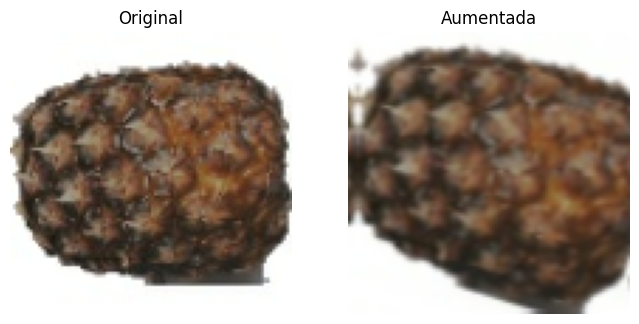

In [ ]:
import matplotlib.pyplot as plt

for imagenes, etiquetas in train_ds.take(1):

    imagen_original = imagenes[0]

    imagen_aumentada = data_augmentation(
        tf.expand_dims(imagen_original, 0)
    )

    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    plt.imshow(imagen_original.numpy().astype("uint8"))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(imagen_aumentada[0].numpy().astype("uint8"))
    plt.title("Aumentada")
    plt.axis("off")

    plt.show()

In [ ]:
# Construir CNN
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
modelo = Sequential([
    data_augmentation,
    Rescaling(1./255),
    Conv2D(32, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(5, activation="softmax")
])

In [ ]:

modelo.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 100, 100, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (1, 100, 100, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (1, 98, 98, 32)        │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (1, 49, 49, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (1, 47, 47, 64)        │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (1, 23, 23, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (1, 21, 21, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (1, 10, 10, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (1, 12800)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (1, 128)               │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (1, 5)                 │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,732,421 (6.61 MB)

 Trainable params: 1,732,421 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compilar modelo

modelo.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Entrenar modelo

historial = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.8730 - loss: 0.3317 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9922 - loss: 0.0234 - val_accuracy: 1.0000 - val_loss: 1.0434e-04
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9990 - loss: 0.0035 - val_accuracy: 1.0000 - val_loss: 2.1223e-05
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9868 - loss: 0.0358 - val_accuracy: 1.0000 - val_loss: 0.0040
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9946 - loss: 0.0174 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9985 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 1.3243e-05
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9990 - loss: 0.0022 - val_accuracy: 1.0000 - val_loss: 1.0992e-05
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9980 - loss: 0.0039 - val_accu

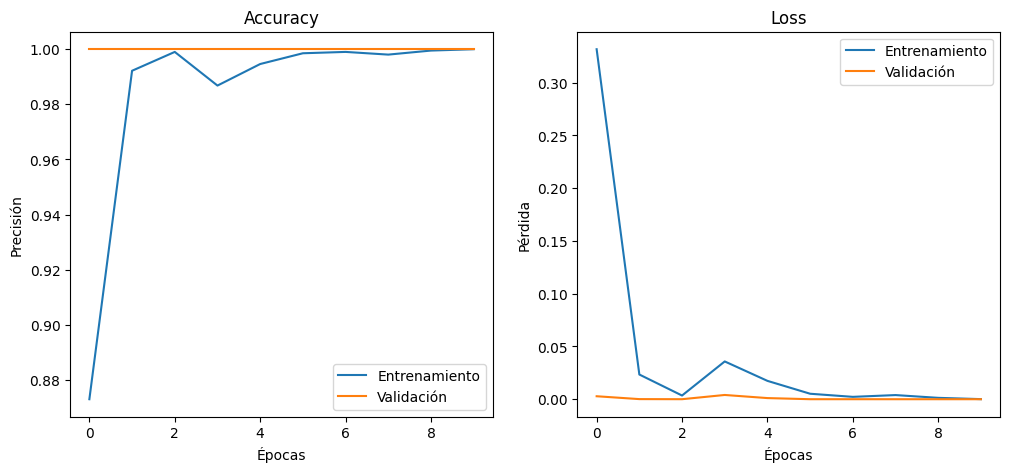

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))


plt.subplot(1,2,1)

plt.plot(
    historial.history['accuracy'],
    label='Entrenamiento'
)

plt.plot(
    historial.history['val_accuracy'],
    label='Validación'
)

plt.title("Accuracy")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()


plt.subplot(1,2,2)

plt.plot(
    historial.history['loss'],
    label='Entrenamiento'
)

plt.plot(
    historial.history['val_loss'],
    label='Validación'
)

plt.title("Loss")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()

plt.show()

In [ ]:

ruta_test = "fruits_dataset/fruits-360_100x100/fruits-360/Test"

test_ds = image_dataset_from_directory(
    ruta_test,
    image_size=(100, 100),
    batch_size=32,
    label_mode="categorical",
    class_names=[
        "Apple Golden 1",
        "Banana 1",
        "Orange 1",
        "Grape Blue 1",
        "Pineapple 1"
    ]
)


Found 980 files belonging to 5 classes.


In [ ]:

loss, accuracy = modelo.evaluate(test_ds)

print("Accuracy:", accuracy)
print("Loss:", loss)

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 1.0000 - loss: 1.2067e-07
Accuracy: 1.0
Loss: 1.2066890064943436e-07


In [ ]:

import numpy as np
from sklearn.metrics import (
    classification_report
)

y_real = []
y_pred = []

for imagenes, etiquetas in test_ds:

    predicciones = modelo.predict(
        imagenes,
        verbose=0
    )

    y_real.extend(
        np.argmax(
            etiquetas.numpy(),
            axis=1
        )
    )

    y_pred.extend(
        np.argmax(
            predicciones,
            axis=1
        )
    )

print(
    classification_report(
        y_real,
        y_pred,
        target_names=[
            "Apple Golden 1",
            "Banana 1",
            "Orange 1",
            "Grape Blue 1",
            "Pineapple 1"
        ]
    )
)

                precision    recall  f1-score   support

Apple Golden 1       1.00      1.00      1.00       160
      Banana 1       1.00      1.00      1.00       166
      Orange 1       1.00      1.00      1.00       160
  Grape Blue 1       1.00      1.00      1.00       328
   Pineapple 1       1.00      1.00      1.00       166

      accuracy                           1.00       980
     macro avg       1.00      1.00      1.00       980
  weighted avg       1.00      1.00      1.00       980



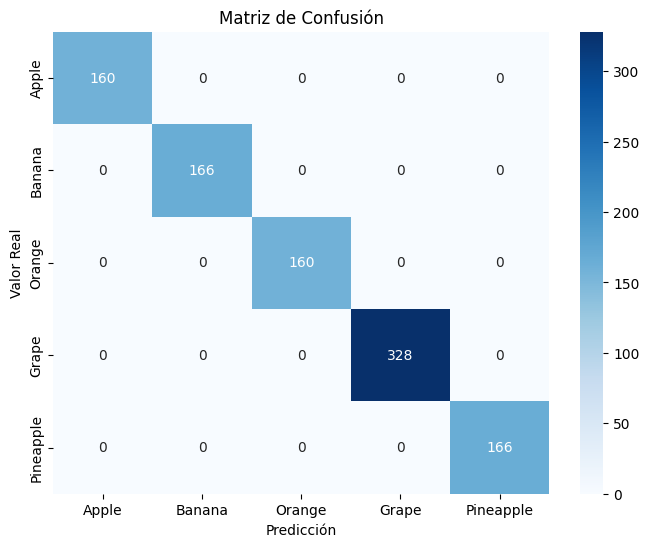

In [ ]:
# Matriz de confusión

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        "Apple",
        "Banana",
        "Orange",
        "Grape",
        "Pineapple"
    ],
    yticklabels=[
        "Apple",
        "Banana",
        "Orange",
        "Grape",
        "Pineapple"
    ]
)

plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.title("Matriz de Confusión")

plt.show()

In [ ]:
clases = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

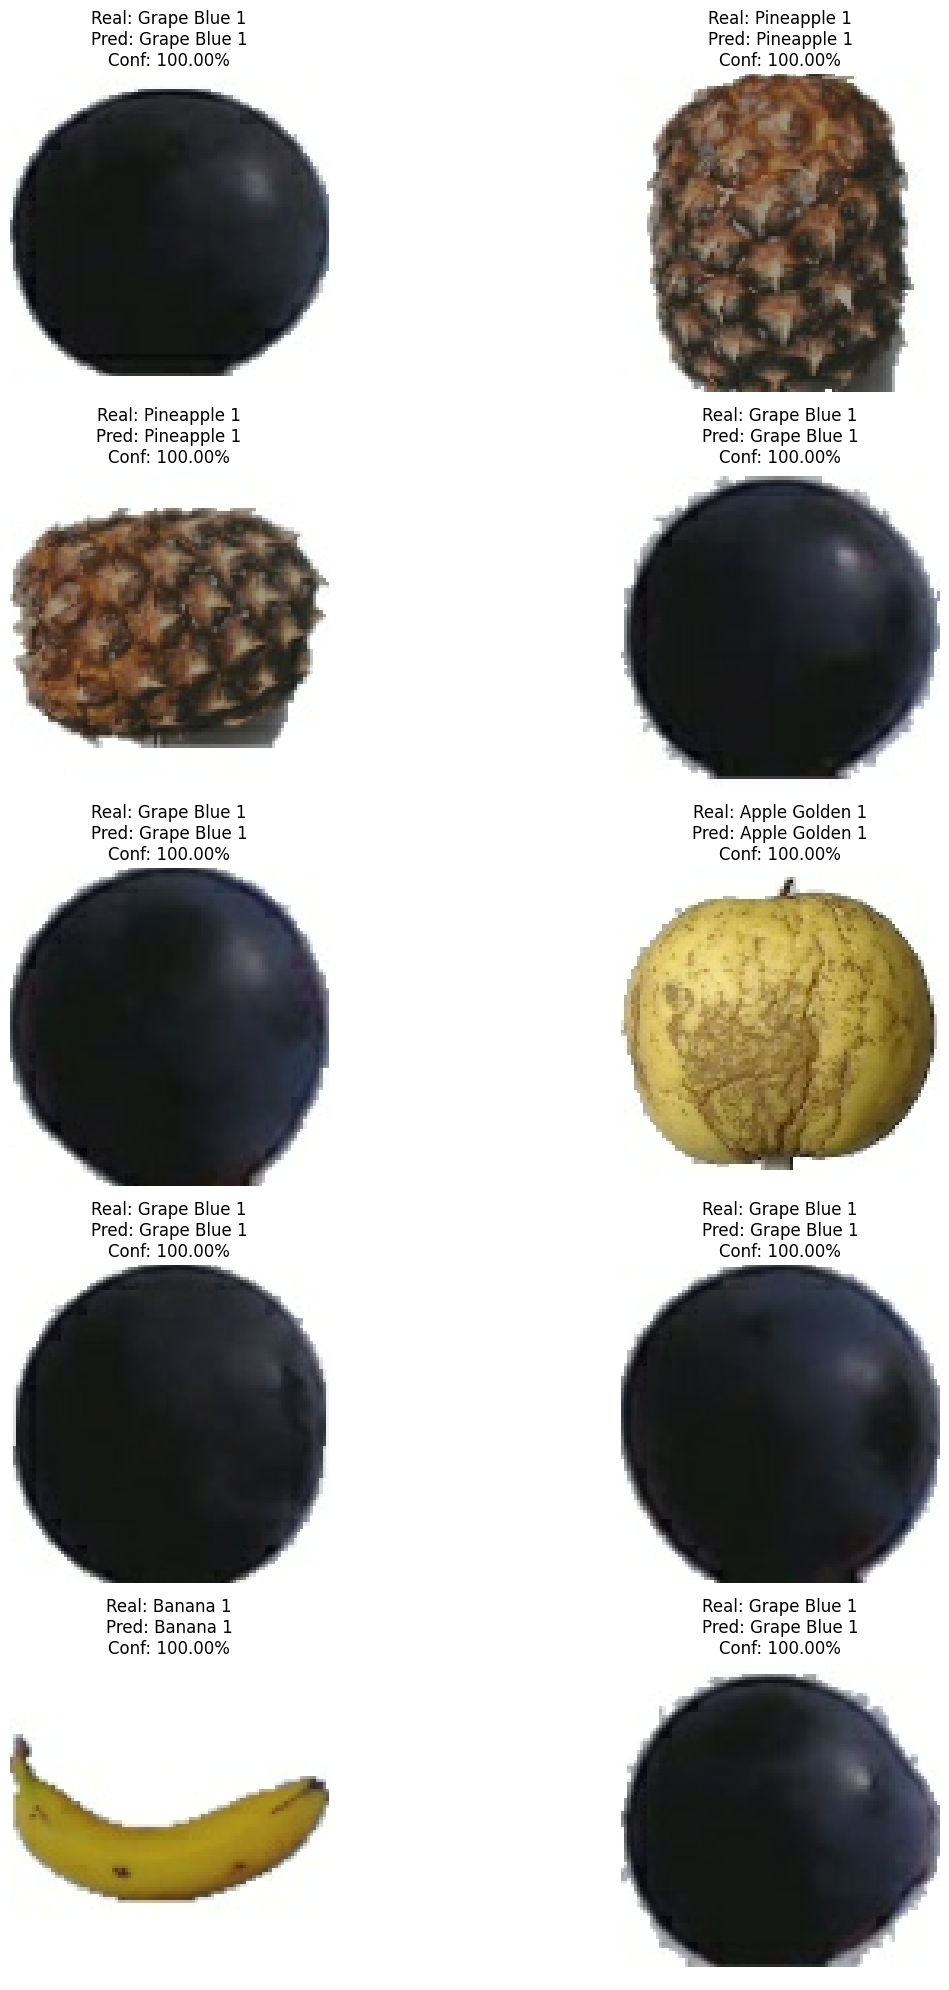

In [ ]:
# Mostrar 10 predicciones

import matplotlib.pyplot as plt
import numpy as np

contador = 0

plt.figure(figsize=(15,20))

for imagenes, etiquetas in test_ds:

    predicciones = modelo.predict(
        imagenes,
        verbose=0
    )

    for i in range(len(imagenes)):

        clase_real = clases[
            np.argmax(etiquetas[i])
        ]

        indice_pred = np.argmax(
            predicciones[i]
        )

        clase_predicha = clases[
            indice_pred
        ]

        confianza = np.max(
            predicciones[i]
        ) * 100

        plt.subplot(5, 2, contador + 1)

        plt.imshow(
            imagenes[i].numpy().astype("uint8")
        )

        plt.title(
            f"Real: {clase_real}\n"
            f"Pred: {clase_predicha}\n"
            f"Conf: {confianza:.2f}%"
        )

        plt.axis("off")

        contador += 1

        if contador == 10:
            break

    if contador == 10:
        break

plt.tight_layout()
plt.show()

In [ ]:
modelo.save("modelo_frutas.keras")

In [ ]:

!ls -lh modelo_frutas.keras

-rw-r--r-- 1 root root 20M Nov  6 02:17 modelo_frutas.keras


In [ ]:
from tensorflow.keras.models import load_model

modelo_cargado = load_model(
    "modelo_frutas.keras"
)

print("Modelo cargado correctamente")

Modelo cargado correctamente


In [ ]:
# Ver nombres de clases

clases = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

print(clases)

['Apple Golden 1', 'Banana 1', 'Orange 1', 'Grape Blue 1', 'Pineapple 1']


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 24.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 65.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image
from tensorflow.keras.models import load_model

modelo = load_model("modelo_frutas.keras")

clases = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

st.title("Clasificador de Frutas con CNN")

st.write(
    "Carga una imagen para obtener una predicción."
)

archivo = st.file_uploader(
    "Selecciona una imagen",
    type=["jpg", "jpeg", "png"]
)

if archivo is not None:

    imagen = Image.open(archivo)

    st.image(
        imagen,
        caption="Imagen cargada",
        use_container_width=True
    )

    imagen = imagen.resize((100, 100))

    imagen = np.array(imagen)

    imagen = imagen / 255.0

    imagen = np.expand_dims(
        imagen,
        axis=0
    )

    prediccion = modelo.predict(
        imagen,
        verbose=0
    )

    indice = np.argmax(prediccion)

    fruta = clases[indice]

    confianza = (
        np.max(prediccion) * 100
    )

    st.success(
        f"Fruta predicha: {fruta}"
    )

    st.info(
        f"Confianza: {confianza:.2f}%"
    )

Writing app.py


In [ ]:
# Verificar aplicación

!ls -lh app.py

-rw-r--r-- 1 root root 1.2K Nov  6 02:27 app.py


In [ ]:
%%writefile requirements.txt

tensorflow
numpy
pandas
matplotlib
seaborn
scikit-learn
pillow
streamlit

Writing requirements.txt


In [ ]:
!cat requirements.txt


tensorflow
numpy
pandas
matplotlib
seaborn
scikit-learn
pillow
streamlit


In [ ]:
%%writefile README.md
# Proyecto CNN para Clasificación de Frutas

## Descripción

Proyecto de Deep Learning desarrollado con TensorFlow y Keras para clasificar imágenes de frutas mediante una Red Neuronal Convolucional (CNN).

Las clases utilizadas fueron:

- Apple Golden 1
- Banana 1
- Orange 1
- Grape Blue 1
- Pineapple 1

## Tecnologías

- Python
- TensorFlow
- Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Streamlit

## Resultados

- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1-Score: 100%

## Estructura del Proyecto

```text
proyecto-cnn-frutas/

├── Proyecto_Final_CNN_Clasificacion_Frutas.ipynb
├── modelo_frutas.keras
├── app.py
├── requirements.txt
└── README.md

Writing README.md


In [ ]:
%%writefile train.py

from tensorflow.keras.models import load_model

print("Archivo de entrenamiento creado")

Writing train.py


In [ ]:
%%writefile train.py

import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Rescaling,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomTranslation,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Ruta del dataset
ruta_train = "fruits_dataset/fruits-360_100x100/fruits-360/Training"

# Dataset entrenamiento
train_ds = image_dataset_from_directory(
    ruta_train,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=(100,100),
    batch_size=32,
    label_mode="categorical",
    class_names=[
        "Apple Golden 1",
        "Banana 1",
        "Orange 1",
        "Grape Blue 1",
        "Pineapple 1"
    ]
)

# Dataset validación
val_ds = image_dataset_from_directory(
    ruta_train,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(100,100),
    batch_size=32,
    label_mode="categorical",
    class_names=[
        "Apple Golden 1",
        "Banana 1",
        "Orange 1",
        "Grape Blue 1",
        "Pineapple 1"
    ]
)

# Data augmentation
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
    RandomTranslation(0.1,0.1)
])

# Modelo CNN
modelo = Sequential([

    data_augmentation,

    Rescaling(1./255),

    Conv2D(32,(3,3),activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(64,(3,3),activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(128,(3,3),activation="relu"),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(128,activation="relu"),

    Dropout(0.3),

    Dense(5,activation="softmax")
])

# Compilar
modelo.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenar
historial = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# Guardar modelo
modelo.save("modelo_frutas.keras")

print("Entrenamiento finalizado")

Overwriting train.py


In [ ]:
%%writefile predict.py

import numpy as np
from PIL import Image
from tensorflow.keras.models import load_model

# Cargar modelo
modelo = load_model("modelo_frutas.keras")

# Clases
clases = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

# Ruta imagen
ruta_imagen = "imagen.jpg"

# Abrir imagen
imagen = Image.open(ruta_imagen)

# Redimensionar
imagen = imagen.resize((100, 100))

# Convertir a array
imagen = np.array(imagen)

# Normalizar
imagen = imagen / 255.0

# Agregar dimensión batch
imagen = np.expand_dims(imagen, axis=0)

# Predicción
prediccion = modelo.predict(imagen)

indice = np.argmax(prediccion)

fruta = clases[indice]

confianza = np.max(prediccion) * 100

print("Clase predicha:", fruta)
print("Confianza:", round(confianza, 2), "%")

Writing predict.py


In [ ]:
!ls -lh

total 8.3G
-rw-r--r-- 1 root root 1.2K Nov  6 02:27 app.py
drwxr-xr-x 7 root root 4.0K Nov  6 00:07 fruits_dataset
-rw-r--r-- 1 root root 8.2G Oct 27 12:54 fruits.zip
-rw-r--r-- 1 root root   70 Nov  6 00:02 kaggle.json
-rw-r--r-- 1 root root  20M Nov  6 02:17 modelo_frutas.keras
-rw-r--r-- 1 root root  784 Nov  6 02:47 predict.py
-rw-r--r-- 1 root root  700 Nov  6 02:38 README.md
-rw-r--r-- 1 root root   74 Nov  6 02:34 requirements.txt
drwxr-xr-x 1 root root 4.0K Nov  4 17:01 sample_data
-rw-r--r-- 1 root root 2.0K Nov  6 02:45 train.py


In [ ]:
!python train.py --help

Found 2923 files belonging to 5 classes.
Using 2047 files for training.
W0000 00:00:1793933451.888575   48864 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Found 2923 files belonging to 5 classes.
Using 876 files for validation.
Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8955 - loss: 0.2754 - val_accuracy: 1.0000 - val_loss: 7.1257e-04
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9951 - loss: 0.0172 - val_accuracy: 0.9909 - val_loss: 0.0189
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9971 - loss: 0.0109 - val_accuracy: 1.0000 - val_loss: 1.9260e-05
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9985 - loss: 0.0037 - val_accuracy: 1.0000 - val_loss: 3.8086e-05
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 1.0000 - loss: 4.4742e-04 - val_accuracy: 1.0000 - val_loss: 2.0523e-06
Epoch 6

In [ ]:
!cat README.md

# Proyecto CNN para Clasificación de Frutas

## Descripción

Proyecto de Deep Learning desarrollado con TensorFlow y Keras para clasificar imágenes de frutas mediante una Red Neuronal Convolucional (CNN).

Las clases utilizadas fueron:

- Apple Golden 1
- Banana 1
- Orange 1
- Grape Blue 1
- Pineapple 1

## Tecnologías

- Python
- TensorFlow
- Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Streamlit

## Resultados

- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1-Score: 100%

## Estructura del Proyecto

```text
proyecto-cnn-frutas/

├── Proyecto_Final_CNN_Clasificacion_Frutas.ipynb
├── modelo_frutas.keras
├── app.py
├── requirements.txt
└── README.md


In [ ]:
%%writefile README.md
# Proyecto CNN para Clasificación de Frutas

## Objetivo

Desarrollar una Red Neuronal Convolucional (CNN) para clasificar imágenes de frutas utilizando TensorFlow y desplegar el modelo mediante una aplicación Streamlit.

## Dataset

Dataset utilizado:

Fruits-360

Clases seleccionadas:

- Apple Golden 1
- Banana 1
- Orange 1
- Grape Blue 1
- Pineapple 1

## Tecnologías Utilizadas

- Python
- TensorFlow
- Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-Learn
- Streamlit

## Arquitectura CNN

Entrada (100x100x3)

→ Conv2D (32)

→ MaxPooling2D

→ Conv2D (64)

→ MaxPooling2D

→ Conv2D (128)

→ MaxPooling2D

→ Flatten

→ Dense (128)

→ Dropout (0.3)

→ Dense (5)

## Resultados

- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1-Score: 100%

## Archivos del Proyecto

- Proyecto_Final_CNN_Clasificacion_Frutas.ipynb
- train.py
- predict.py
- modelo_frutas.keras
- app.py
- requirements.txt

## Instalación

```bash
pip install -r requirements.txt

Overwriting README.md


In [ ]:
# Ver scripts principales

!ls -lh train.py predict.py app.py

-rw-r--r-- 1 root root 1.2K Nov  6 02:27 app.py
-rw-r--r-- 1 root root  784 Nov  6 02:47 predict.py
-rw-r--r-- 1 root root 2.0K Nov  6 02:45 train.py


In [ ]:
# Ver contenido predict.py

!cat predict.py


import numpy as np
from PIL import Image
from tensorflow.keras.models import load_model

# Cargar modelo
modelo = load_model("modelo_frutas.keras")

# Clases
clases = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

# Ruta imagen
ruta_imagen = "imagen.jpg"

# Abrir imagen
imagen = Image.open(ruta_imagen)

# Redimensionar
imagen = imagen.resize((100, 100))

# Convertir a array
imagen = np.array(imagen)

# Normalizar
imagen = imagen / 255.0

# Agregar dimensión batch
imagen = np.expand_dims(imagen, axis=0)

# Predicción
prediccion = modelo.predict(imagen)

indice = np.argmax(prediccion)

fruta = clases[indice]

confianza = np.max(prediccion) * 100

print("Clase predicha:", fruta)
print("Confianza:", round(confianza, 2), "%")


In [ ]:
!find /content -name "*.ipynb"

In [ ]:
!ls -lh README.md requirements.txt train.py predict.py app.py

-rw-r--r-- 1 root root 1.2K Nov  6 02:27 app.py
-rw-r--r-- 1 root root  784 Nov  6 02:47 predict.py
-rw-r--r-- 1 root root  988 Nov  6 02:55 README.md
-rw-r--r-- 1 root root   74 Nov  6 02:34 requirements.txt
-rw-r--r-- 1 root root 2.0K Nov  6 02:45 train.py


In [ ]:

!ls -lh modelo_frutas.keras

-rw-r--r-- 1 root root 20M Nov  6 02:51 modelo_frutas.keras


In [ ]:
from google.colab import files

files.download("app.py")
files.download("train.py")
files.download("predict.py")
files.download("requirements.txt")
files.download("README.md")
files.download("modelo_frutas.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Clases del entrenamiento:")
print(train_ds.class_names if hasattr(train_ds, "class_names") else "No disponibles")

print("\nForma de salida del modelo:")
print(modelo.output_shape)

print("\nPredicción de una imagen de piña:")

Clases del entrenamiento:
['Apple Golden 1', 'Banana 1', 'Orange 1', 'Grape Blue 1', 'Pineapple 1']

Forma de salida del modelo:
(1, 5)

Predicción de una imagen de piña:


In [ ]:
import numpy as np

imagenes, etiquetas = next(iter(test_ds))

predicciones = modelo.predict(imagenes, verbose=0)

for i in range(5):
    real = test_ds.class_names[np.argmax(etiquetas[i])]
    predicha = test_ds.class_names[np.argmax(predicciones[i])]

    print("Real:", real)
    print("Predicción:", predicha)
    print("Confianza:", round(float(np.max(predicciones[i])) * 100, 2), "%")
    print("--------------------")

Real: Grape Blue 1
Predicción: Grape Blue 1
Confianza: 100.0 %
--------------------
Real: Grape Blue 1
Predicción: Grape Blue 1
Confianza: 100.0 %
--------------------
Real: Grape Blue 1
Predicción: Grape Blue 1
Confianza: 100.0 %
--------------------
Real: Apple Golden 1
Predicción: Apple Golden 1
Confianza: 100.0 %
--------------------
Real: Apple Golden 1
Predicción: Apple Golden 1
Confianza: 100.0 %
--------------------


Fruta real: Pineapple 1
Fruta predicha: Pineapple 1
Confianza: 100.0 %


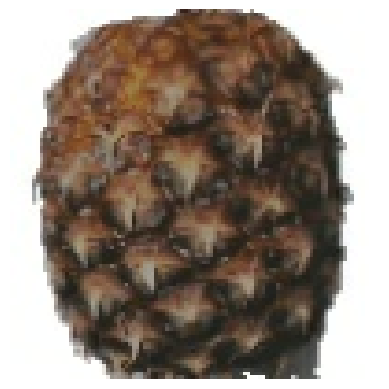

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

for imagenes, etiquetas in test_ds:
    for i in range(len(imagenes)):
        if np.argmax(etiquetas[i]) == 4:
            imagen_prueba = imagenes[i]

            prediccion = modelo.predict(
                np.expand_dims(imagen_prueba, axis=0),
                verbose=0
            )

            print("Fruta real: Pineapple 1")
            print("Fruta predicha:", test_ds.class_names[np.argmax(prediccion)])
            print("Confianza:", round(float(np.max(prediccion)) * 100, 2), "%")

            plt.imshow(imagen_prueba.numpy().astype("uint8"))
            plt.axis("off")
            plt.show()

            break
    else:
        continue
    break

In [ ]:
modelo.save("modelo_frutas.keras")

In [ ]:
from google.colab import files
files.download("modelo_frutas.keras")

FileNotFoundError: Cannot find file: modelo_frutas.keras

In [ ]:
import os

print(os.listdir())

['.config', 'sample_data']


In [4]:
import os

print(os.listdir())

['.config', 'sample_data']


In [5]:
!pip install -q kaggle

In [6]:
from google.colab import userdata

In [8]:
import os

for carpeta, subcarpetas, archivos in os.walk("/content"):
    for archivo in archivos:
        if archivo.endswith(".json"):
            print(os.path.join(carpeta, archivo))

/content/.config/.last_update_check.json
/content/sample_data/anscombe.json


In [9]:
from google.colab import files

archivos = files.upload()

Saving kaggle.json to kaggle.json


In [10]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Credenciales configuradas correctamente")

Credenciales configuradas correctamente


In [11]:
!kaggle datasets list -s fruits-360

ref                                                  title                                               size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------  --------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
moltean/fruits                                       Fruits-360 dataset                            8804326357  2026-10-27 08:32:54.893000         267559       3556                1  
barisyasli/fruit360                                  fruits-360                                     362079657  2020-04-22 01:53:20.160000            807          8           0.4375  
souro12/ccxzvv                                       Fruits Images - 5 classes                       15299044  2020-04-01 09:49:55.777000            889         10           0.8125  
ishandandekar/fruitimagedataset                      Fruit-Image-Dataset             

In [12]:
!kaggle datasets download -d moltean/fruits

Dataset URL: https://www.kaggle.com/datasets/moltean/fruits
License(s): CC-BY-SA-4.0
100% 8.20G/8.20G [01:51<00:00, 78.6MB/s]



In [13]:
import zipfile

with zipfile.ZipFile("/content/fruits.zip", "r") as zip_ref:
    zip_ref.extractall("/content/fruits_dataset")

print("Conjunto de datos descomprimido correctamente")

Conjunto de datos descomprimido correctamente


In [14]:
import os

for ruta, carpetas, archivos in os.walk("/content/fruits_dataset"):
    nivel = ruta.replace("/content/fruits_dataset", "").count(os.sep)
    if nivel <= 3:
        print("  " * nivel + os.path.basename(ruta) + "/")

fruits_dataset/
  fruits-360_100x100/
    fruits-360/
      Training/
      Test/
  fruits-360_3-body-problem/
    fruits-360-3-body-problem/
      Training/
      Test/
  fruits-360_meta/
    fruits-360-meta/
      Papers/
      Meta/
  fruits-360_multi/
    test-multiple_fruits/
  fruits-360_original-size/
    fruits-360-original-size/
      Papers/
      Training/
      Test/
      Validation/


In [15]:
import os

ruta = "/content/fruits_dataset/fruits-360_100x100/fruits-360/Training"

for fruta in sorted(os.listdir(ruta)):
    carpeta = os.path.join(ruta, fruta)
    if os.path.isdir(carpeta):
        print(fruta, ":", len(os.listdir(carpeta)), "imágenes")

Almonds 1 : 232 imágenes
Apple 10 : 699 imágenes
Apple 11 : 430 imágenes
Apple 12 : 466 imágenes
Apple 13 : 699 imágenes
Apple 14 : 466 imágenes
Apple 17 : 610 imágenes
Apple 18 : 724 imágenes
Apple 19 : 729 imágenes
Apple 20 : 702 imágenes
Apple 21 : 488 imágenes
Apple 22 : 696 imágenes
Apple 23 : 470 imágenes
Apple 5 : 440 imágenes
Apple 6 : 473 imágenes
Apple 7 : 694 imágenes
Apple 8 : 687 imágenes
Apple 9 : 694 imágenes
Apple Braeburn 1 : 492 imágenes
Apple Crimson Snow 1 : 444 imágenes
Apple Golden 1 : 480 imágenes
Apple Golden 2 : 492 imágenes
Apple Golden 3 : 481 imágenes
Apple Granny Smith 1 : 492 imágenes
Apple Pink Lady 1 : 456 imágenes
Apple Red 1 : 492 imágenes
Apple Red 2 : 492 imágenes
Apple Red 3 : 429 imágenes
Apple Red Delicious 1 : 490 imágenes
Apple Red Yellow 1 : 492 imágenes
Apple Red Yellow 2 : 672 imágenes
Apricot 1 : 492 imágenes
Avocado 1 : 427 imágenes
Avocado 2 : 491 imágenes
Avocado Black 1 : 702 imágenes
Avocado Black 2 : 738 imágenes
Avocado Green 1 : 702 

In [16]:
import os

ruta = "/content/fruits_dataset/fruits-360_100x100/fruits-360/Test"

frutas = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

for fruta in frutas:
    carpeta = os.path.join(ruta, fruta)
    print(fruta, ":", len(os.listdir(carpeta)), "imágenes")

Apple Golden 1 : 160 imágenes
Banana 1 : 166 imágenes
Orange 1 : 160 imágenes
Grape Blue 1 : 328 imágenes
Pineapple 1 : 166 imágenes


In [17]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os

ruta_entrenamiento = "/content/fruits_dataset/fruits-360_100x100/fruits-360/Training"
ruta_prueba = "/content/fruits_dataset/fruits-360_100x100/fruits-360/Test"

clases = [
    "Apple Golden 1",
    "Banana 1",
    "Orange 1",
    "Grape Blue 1",
    "Pineapple 1"
]

print("TensorFlow:", tf.__version__)
print("Clases:", clases)
print("GPU disponible:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
Clases: ['Apple Golden 1', 'Banana 1', 'Orange 1', 'Grape Blue 1', 'Pineapple 1']
GPU disponible: True


In [18]:
from tensorflow.keras.utils import image_dataset_from_directory

datos_entrenamiento = image_dataset_from_directory(
    ruta_entrenamiento,
    class_names=clases,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(100, 100),
    batch_size=32,
    label_mode="categorical"
)

datos_validacion = image_dataset_from_directory(
    ruta_entrenamiento,
    class_names=clases,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(100, 100),
    batch_size=32,
    label_mode="categorical"
)

print("Imágenes de entrenamiento:", datos_entrenamiento.cardinality().numpy())
print("Lotes de validación:", datos_validacion.cardinality().numpy())

Found 2923 files belonging to 5 classes.
Using 2339 files for training.
Found 2923 files belonging to 5 classes.
Using 584 files for validation.
Imágenes de entrenamiento: 74
Lotes de validación: 19


In [19]:
from tensorflow import keras
from tensorflow.keras import layers

modelo = keras.Sequential([
    layers.Input(shape=(100, 100, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(5, activation="softmax")
])

modelo.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 100, 100, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
parada = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

ajuste = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=2,
    factor=0.5,
    min_lr=0.00001
)

print("Configuración del entrenamiento lista")

Configuración del entrenamiento lista


In [21]:
historial = modelo.fit(
    datos_entrenamiento,
    validation_data=datos_validacion,
    epochs=25,
    callbacks=[parada, ajuste]
)

Epoch 1/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.8093 - loss: 0.5910 - val_accuracy: 0.9983 - val_loss: 0.0246 - learning_rate: 0.0010
Epoch 2/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9949 - loss: 0.0216 - val_accuracy: 1.0000 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 3/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 0.0048 - val_accuracy: 1.0000 - val_loss: 1.2775e-04 - learning_rate: 0.0010
Epoch 4/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9957 - loss: 0.0160 - val_accuracy: 0.9897 - val_loss: 0.0267 - learning_rate: 0.0010
Epoch 5/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9974 - loss: 0.0072 - val_accuracy: 1.0000 - val_loss: 2.1453e-04 - learning_rate: 0.0010
Epoch 6/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 5.1572e-05 - learning_rate: 5.0000e-04
Epoch 7/25
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss:

In [22]:
print("Entrenamiento finalizado")
print("Épocas ejecutadas:", len(historial.history["loss"]))

Entrenamiento finalizado
Épocas ejecutadas: 18


In [23]:
datos_prueba = image_dataset_from_directory(
    ruta_prueba,
    class_names=clases,
    image_size=(100, 100),
    batch_size=32,
    label_mode="categorical",
    shuffle=False
)

print("Lotes de prueba:", datos_prueba.cardinality().numpy())

Found 980 files belonging to 5 classes.
Lotes de prueba: 31


In [24]:
resultado = modelo.evaluate(datos_prueba)

print("Pérdida en prueba:", resultado[0])
print("Precisión en prueba:", resultado[1] * 100, "%")

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 1.0000 - loss: 1.2788e-05
Pérdida en prueba: 1.2788004823960364e-05
Precisión en prueba: 100.0 %


In [25]:
modelo.save("/content/modelo_frutas.keras")

print("Modelo guardado correctamente")

Modelo guardado correctamente


In [26]:
from google.colab import files
files.download("/content/modelo_frutas.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>